# Forecasting Housing Affordability to 2035
## Classical vs Modern Time-Series Models

This notebook forecasts housing affordability for 26 countries through 2035 using a leakage-aware protocol.

The dataset contains indexed real house prices and real disposable income. The published affordability variable is approximately:

$$
\text{affordability proxy}_{c,t} = 100 \times \frac{\text{real house price index}_{c,t}}{\text{real personal disposable income}_{c,t}}
$$

That means directly predicting `affordability_proxy` from the two real component indexes would be target leakage. Instead, this notebook forecasts the two components separately and then derives affordability from the forecasts.

### Models compared

- **Drift baseline:** random walk with country-specific trend.
- **ETS:** exponential smoothing, a classical structural time-series model.
- **ARIMA:** compact AIC-selected ARIMA grid per country and component.
- **Global Gradient Boosting:** panel ML model using lag features across all countries.
- **PatchMixer Lite:** small PyTorch patch/mixer neural model inspired by modern long-horizon forecasting ideas such as PatchTST, TSMixer, and TimeMixer.

The goal is not to claim that the most complex model must win. For small annual macro panels, a disciplined baseline can beat a neural model. That result is useful.

In [1]:
import os
import math
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("notebook")

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Load Data

The cell below works both locally and on Kaggle. If the Kaggle dataset folder name changes, add the new path to `CANDIDATE_PATHS`.

In [2]:
CANDIDATE_PATHS = [
    Path("/kaggle/input/housing-affordability-26-countries-1975-2025/accessibilit-economica-alloggi-26-paesi-1975-2025.csv"),
    Path("/kaggle/input/housing-affordability-26-countries-1975-2025/accessibilit-economica-alloggi-26-paesi-1975-2025.csv"),
    Path("accessibilit-economica-alloggi-26-paesi-1975-2025.csv"),
    Path("/kaggle/input/datasets/lucalullo/housing-affordability-26-countries-1975-2025/accessibilit-economica-alloggi-26-paesi-1975-2025.csv"),
]

DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset CSV not found. Update CANDIDATE_PATHS with the Kaggle input path.")

raw = pd.read_csv(DATA_PATH)
raw = raw.sort_values(["country", "year"]).reset_index(drop=True)

print(f"Loaded: {DATA_PATH}")
print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]:,} columns")
raw.head()

Loaded: /kaggle/input/datasets/lucalullo/housing-affordability-26-countries-1975-2025/accessibilit-economica-alloggi-26-paesi-1975-2025.csv
Shape: 1,326 rows x 8 columns


,country,iso,year,house_price_index,personal_disposable_income,real_house_price_index,real_personal_disposable_income,affordability_proxy
0,Australia,AUS,1975,2.83,7.19,21.89,55.72,39.29
1,Australia,AUS,1976,3.19,8.11,21.65,55.04,39.34
2,Australia,AUS,1977,3.48,8.91,21.43,54.88,39.05
3,Australia,AUS,1978,3.75,9.85,21.28,55.91,38.06
4,Australia,AUS,1979,4.20,10.80,21.75,55.94,38.88


In [3]:
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(),
})

print("Year range:", raw["year"].min(), "to", raw["year"].max())
print("Countries:", raw["country"].nunique())
print("Duplicate rows:", raw.duplicated().sum())
print("Balanced country-year panel:", raw.groupby("country")["year"].nunique().nunique() == 1)

display(summary)
display(raw.describe().T)

Year range: 1975 to 2025
Countries: 26
Duplicate rows: 0
Balanced country-year panel: True


,dtype,missing,unique
country,object,0,26
iso,object,0,26
year,int64,0,51
house_price_index,float64,0,1187
personal_disposable_income,float64,0,1179
real_house_price_index,float64,0,1228
real_personal_disposable_income,float64,0,1165
affordability_proxy,float64,0,1230


,count,mean,std,min,25%,50%,75%,max
year,"1,326.00","2,000.00",14.73,"1,975.00","1,987.00","2,000.00","2,013.00","2,025.00"
house_price_index,"1,326.00",45.95,33.07,0.00,16.98,42.14,69.87,162.30
personal_disposable_income,"1,326.00",46.02,28.42,0.00,22.34,44.83,68.81,106.49
real_house_price_index,"1,326.00",73.16,30.65,16.14,49.11,71.76,97.08,181.47
real_personal_disposable_income,"1,326.00",73.15,18.67,16.19,58.66,73.46,88.96,107.73
affordability_proxy,"1,326.00",102.96,60.88,37.30,75.52,96.02,109.50,725.91


## 2. Sanity Check: Affordability Is a Derived Ratio

Before modeling, verify the mathematical relation. This matters because a notebook that predicts `affordability_proxy` from `real_house_price_index` and `real_personal_disposable_income` is not a real forecasting exercise.

In [4]:
ratio_check = 100 * raw["real_house_price_index"] / raw["real_personal_disposable_income"]
abs_error = (raw["affordability_proxy"] - ratio_check).abs()

print(f"Max absolute difference from ratio formula: {abs_error.max():.6f}")
print(f"Mean absolute difference from ratio formula: {abs_error.mean():.6f}")

zero_report = raw[["house_price_index", "personal_disposable_income"]].eq(0).sum()
print("\nZero values in nominal index columns:")
print(zero_report)

Max absolute difference from ratio formula: 0.004999
Mean absolute difference from ratio formula: 0.002493

Zero values in nominal index columns:
house_price_index             31
personal_disposable_income    30
dtype: int64


## 3. Visual Baseline

The proxy is an index ratio, not a literal house-price-to-income multiple. Higher values mean real house prices are high relative to real disposable income compared with the index base.

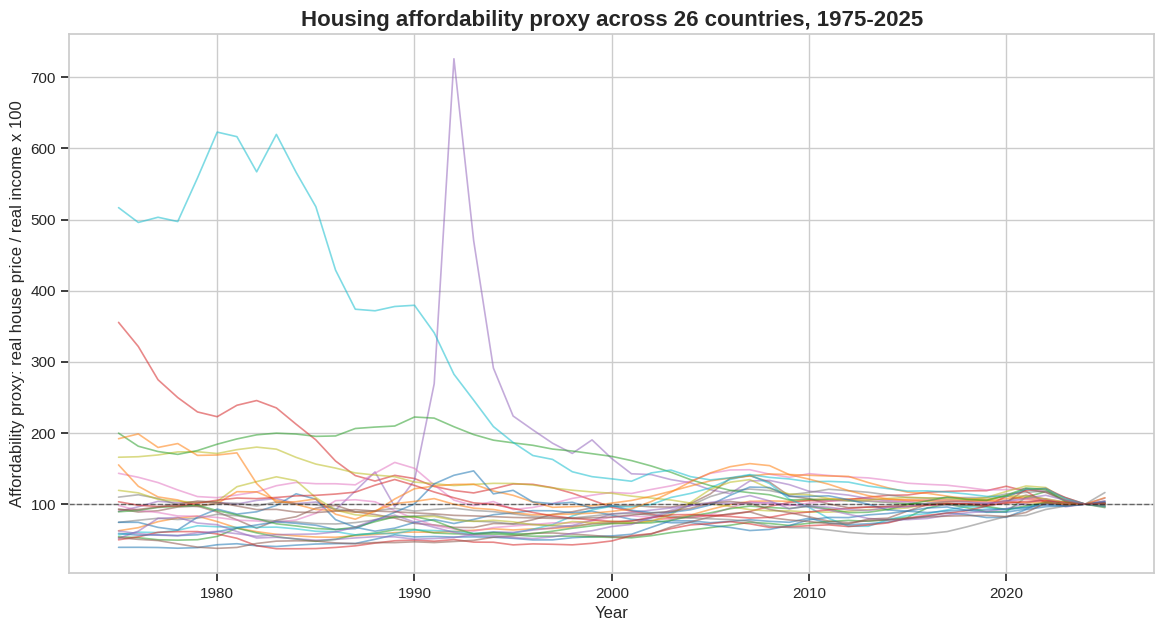

In [5]:
fig, ax = plt.subplots(figsize=(14, 7))
for country, g in raw.groupby("country"):
    ax.plot(g["year"], g["affordability_proxy"], lw=1.2, alpha=0.55)

ax.set_title("Housing affordability proxy across 26 countries, 1975-2025", fontsize=16, weight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Affordability proxy: real house price / real income x 100")
ax.axhline(100, color="black", lw=1, ls="--", alpha=0.5)
plt.show()

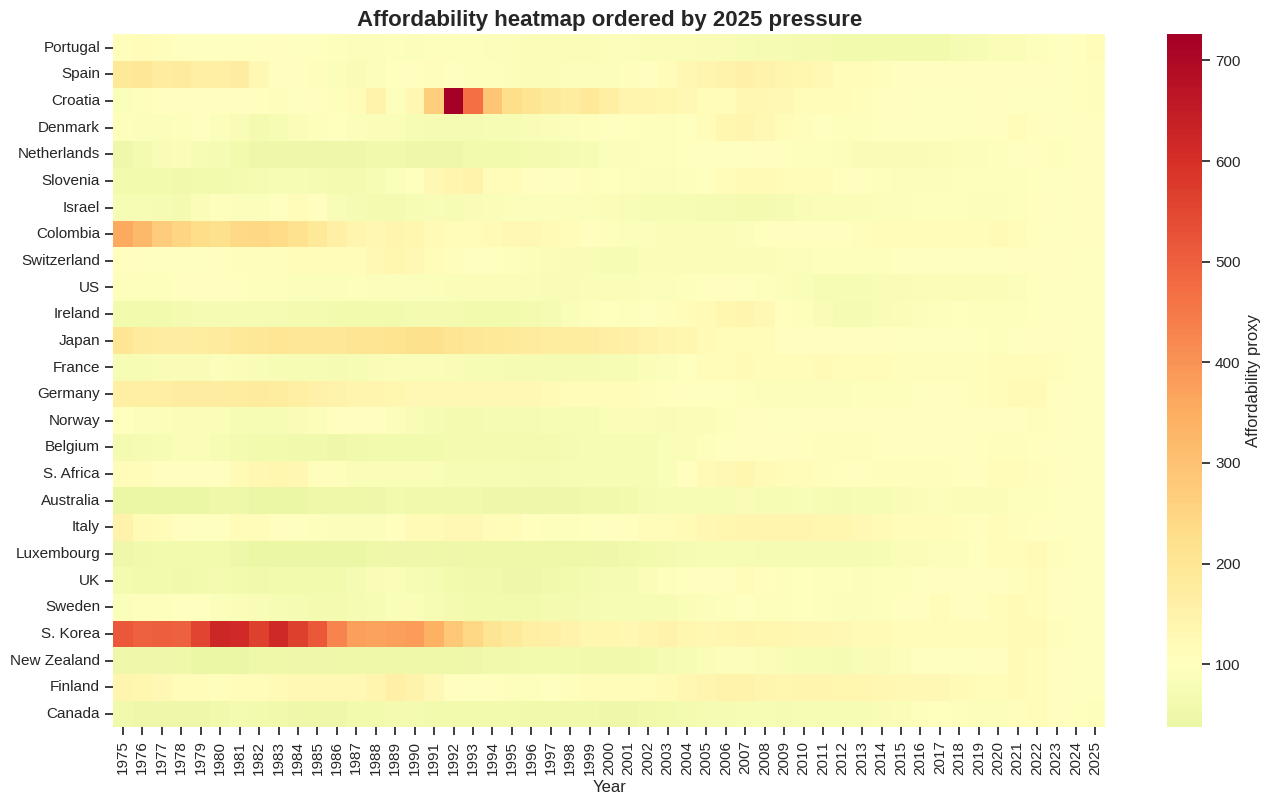

In [6]:
heat = raw.pivot(index="country", columns="year", values="affordability_proxy")
ordered = heat[2025].sort_values(ascending=False).index

plt.figure(figsize=(16, 9))
sns.heatmap(
    heat.loc[ordered],
    cmap="RdYlGn_r",
    center=100,
    linewidths=0.0,
    cbar_kws={"label": "Affordability proxy"},
)
plt.title("Affordability heatmap ordered by 2025 pressure", fontsize=16, weight="bold")
plt.xlabel("Year")
plt.ylabel("")
plt.show()

## 4. Leakage-Aware Forecasting Design

We forecast in log space:

$$
\log A_{c,t} = \log H_{c,t} - \log I_{c,t} + \log(100)
$$

where:

- $H_{c,t}$ is `real_house_price_index`
- $I_{c,t}$ is `real_personal_disposable_income`

Backtest protocol:

- Train through **2015**.
- Forecast **2016-2025** recursively.
- Compare derived affordability forecasts against observed `affordability_proxy`.
- Refit on all data through 2025.
- Forecast **2026-2035**.

In [7]:
COMPONENTS = ["real_house_price_index", "real_personal_disposable_income"]
ID_COLS = ["country", "iso", "year"]

panel = raw[ID_COLS + COMPONENTS].melt(
    id_vars=ID_COLS,
    value_vars=COMPONENTS,
    var_name="component",
    value_name="value",
)
panel["y"] = np.log(panel["value"].clip(lower=1e-8))
panel = panel.sort_values(["country", "component", "year"]).reset_index(drop=True)

ORIGIN = 2015
BACKTEST_HORIZON = 10
FORECAST_ORIGIN = int(raw["year"].max())
FORECAST_END = 2035
FORECAST_HORIZON = FORECAST_END - FORECAST_ORIGIN

print(panel.head())
print(f"Backtest: train <= {ORIGIN}, forecast {ORIGIN + 1}-{ORIGIN + BACKTEST_HORIZON}")
print(f"Final forecast: train <= {FORECAST_ORIGIN}, forecast {FORECAST_ORIGIN + 1}-{FORECAST_END}")

     country  iso  year               component  value    y
0  Australia  AUS  1975  real_house_price_index  21.89 3.09
1  Australia  AUS  1976  real_house_price_index  21.65 3.08
2  Australia  AUS  1977  real_house_price_index  21.43 3.06
3  Australia  AUS  1978  real_house_price_index  21.28 3.06
4  Australia  AUS  1979  real_house_price_index  21.75 3.08
Backtest: train <= 2015, forecast 2016-2025
Final forecast: train <= 2025, forecast 2026-2035


## 5. Metrics and Conversion Utilities

In [8]:
def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + eps)) * 100


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def component_forecasts_to_affordability(pred_long):
    """Convert component log forecasts into affordability forecasts."""
    wide = (
        pred_long
        .pivot_table(index=["country", "iso", "year"], columns="component", values="yhat", aggfunc="mean")
        .reset_index()
    )
    wide.columns.name = None
    wide["real_house_price_index_hat"] = np.exp(wide["real_house_price_index"])
    wide["real_personal_disposable_income_hat"] = np.exp(wide["real_personal_disposable_income"])
    wide["affordability_hat"] = 100 * np.exp(
        wide["real_house_price_index"] - wide["real_personal_disposable_income"]
    )
    return wide[[
        "country", "iso", "year",
        "real_house_price_index_hat",
        "real_personal_disposable_income_hat",
        "affordability_hat",
    ]]


def evaluate_affordability(pred_aff, actual_df, model_name):
    merged = pred_aff.merge(
        actual_df[["country", "iso", "year", "affordability_proxy"]],
        on=["country", "iso", "year"],
        how="inner",
    )
    y_true = merged["affordability_proxy"].values
    y_pred = merged["affordability_hat"].values
    return {
        "model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "sMAPE": smape(y_true, y_pred),
        "bias": np.mean(y_pred - y_true),
        "rows": len(merged),
    }


def add_model_name(df, model_name):
    out = df.copy()
    out["model"] = model_name
    return out

## 6. Classical Models

The classical models are fitted separately for every country and component.

In [9]:
def _series_forecast_years(origin, horizon):
    return list(range(origin + 1, origin + horizon + 1))


def forecast_drift(panel_df, origin, horizon):
    rows = []
    train = panel_df[panel_df["year"] <= origin]
    future_years = _series_forecast_years(origin, horizon)

    for (country, iso, component), g in train.groupby(["country", "iso", "component"]):
        g = g.sort_values("year")
        y = g["y"].values
        if len(y) < 2:
            slope = 0.0
        else:
            slope = (y[-1] - y[0]) / (len(y) - 1)
        yhat = y[-1] + slope * np.arange(1, horizon + 1)
        rows.extend({
            "country": country,
            "iso": iso,
            "component": component,
            "year": year,
            "yhat": pred,
        } for year, pred in zip(future_years, yhat))

    return pd.DataFrame(rows)


def forecast_ets(panel_df, origin, horizon):
    try:
        from statsmodels.tsa.holtwinters import ExponentialSmoothing
    except Exception as exc:
        print(f"statsmodels ETS unavailable; falling back to Drift. Reason: {exc}")
        return forecast_drift(panel_df, origin, horizon)

    rows = []
    train = panel_df[panel_df["year"] <= origin]
    future_years = _series_forecast_years(origin, horizon)

    for (country, iso, component), g in train.groupby(["country", "iso", "component"]):
        y = g.sort_values("year")["y"].astype(float).values
        try:
            fit = ExponentialSmoothing(
                y,
                trend="add",
                damped_trend=True,
                seasonal=None,
                initialization_method="estimated",
            ).fit(optimized=True)
            yhat = np.asarray(fit.forecast(horizon), dtype=float)
        except Exception:
            yhat = forecast_drift(g, origin, horizon)["yhat"].values

        rows.extend({
            "country": country,
            "iso": iso,
            "component": component,
            "year": year,
            "yhat": pred,
        } for year, pred in zip(future_years, yhat))

    return pd.DataFrame(rows)


def forecast_arima(panel_df, origin, horizon):
    try:
        from statsmodels.tsa.arima.model import ARIMA
    except Exception as exc:
        print(f"statsmodels ARIMA unavailable; falling back to Drift. Reason: {exc}")
        return forecast_drift(panel_df, origin, horizon)

    candidate_orders = [
        (0, 1, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1),
        (2, 1, 0), (0, 1, 2), (2, 1, 1), (1, 1, 2),
    ]

    rows = []
    train = panel_df[panel_df["year"] <= origin]
    future_years = _series_forecast_years(origin, horizon)

    for (country, iso, component), g in train.groupby(["country", "iso", "component"]):
        y = g.sort_values("year")["y"].astype(float).values
        best_fit = None
        best_aic = np.inf

        for order in candidate_orders:
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    fit = ARIMA(
                        y,
                        order=order,
                        enforce_stationarity=False,
                        enforce_invertibility=False,
                    ).fit()
                if np.isfinite(fit.aic) and fit.aic < best_aic:
                    best_aic = fit.aic
                    best_fit = fit
            except Exception:
                continue

        if best_fit is None:
            yhat = forecast_drift(g, origin, horizon)["yhat"].values
        else:
            yhat = np.asarray(best_fit.forecast(steps=horizon), dtype=float)

        rows.extend({
            "country": country,
            "iso": iso,
            "component": component,
            "year": year,
            "yhat": pred,
        } for year, pred in zip(future_years, yhat))

    return pd.DataFrame(rows)

## 7. Global Gradient Boosting Model

This is a panel model. It learns from all countries at once using lag features, rolling summaries, year, country, and component identity.

For annual macro data, this style of model is often a hard baseline to beat because it borrows cross-country structure without requiring a large deep-learning training set.

In [10]:
def _make_ohe():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def make_lag_features(panel_df, max_lag=8):
    x = panel_df.sort_values(["country", "component", "year"]).copy()
    keys = ["country", "component"]
    grp = x.groupby(keys)["y"]

    for lag in range(1, max_lag + 1):
        x[f"lag_{lag}"] = grp.shift(lag)

    x["roll3_mean"] = grp.transform(lambda s: s.shift(1).rolling(3).mean())
    x["roll5_mean"] = grp.transform(lambda s: s.shift(1).rolling(5).mean())
    x["diff1"] = grp.diff(1)
    x["diff3"] = x["lag_1"] - x["lag_4"]
    x["year_norm"] = (x["year"] - x["year"].min()) / (x["year"].max() - x["year"].min())
    return x


def build_ml_pipeline(max_lag=8):
    numeric_features = [f"lag_{i}" for i in range(1, max_lag + 1)] + [
        "roll3_mean", "roll5_mean", "diff1", "diff3", "year_norm"
    ]
    categorical_features = ["country", "component"]

    pre = ColumnTransformer(
        transformers=[
            ("num", "passthrough", numeric_features),
            ("cat", _make_ohe(), categorical_features),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

    model = HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=0.045,
        max_iter=500,
        max_leaf_nodes=15,
        min_samples_leaf=12,
        l2_regularization=0.03,
        random_state=SEED,
    )

    return Pipeline([("pre", pre), ("model", model)]), numeric_features, categorical_features


def _recursive_feature_row(history, country, iso, component, year, max_lag=8):
    hist = history[(history["country"] == country) & (history["component"] == component)].sort_values("year")
    y = hist["y"].values
    row = {
        "country": country,
        "iso": iso,
        "component": component,
        "year": year,
        "year_norm": (year - panel["year"].min()) / (FORECAST_END - panel["year"].min()),
    }
    for lag in range(1, max_lag + 1):
        row[f"lag_{lag}"] = y[-lag] if len(y) >= lag else np.nan
    row["roll3_mean"] = np.mean(y[-3:]) if len(y) >= 3 else np.nan
    row["roll5_mean"] = np.mean(y[-5:]) if len(y) >= 5 else np.nan
    row["diff1"] = y[-1] - y[-2] if len(y) >= 2 else 0.0
    row["diff3"] = y[-1] - y[-4] if len(y) >= 4 else 0.0
    return row


def forecast_global_gbdt(panel_df, origin, horizon, max_lag=8):
    train_panel = panel_df[panel_df["year"] <= origin].copy()
    lagged = make_lag_features(train_panel, max_lag=max_lag)
    train = lagged.dropna().copy()

    pipe, numeric_features, categorical_features = build_ml_pipeline(max_lag=max_lag)
    feature_cols = numeric_features + categorical_features
    pipe.fit(train[feature_cols], train["y"])

    history = train_panel.copy()
    future_rows = []

    template = (
        train_panel[["country", "iso", "component"]]
        .drop_duplicates()
        .sort_values(["country", "component"])
        .reset_index(drop=True)
    )

    for year in _series_forecast_years(origin, horizon):
        x_rows = [
            _recursive_feature_row(history, r.country, r.iso, r.component, year, max_lag=max_lag)
            for r in template.itertuples(index=False)
        ]
        x_future = pd.DataFrame(x_rows)
        x_future[numeric_features] = x_future[numeric_features].ffill().bfill().fillna(0)
        yhat = pipe.predict(x_future[feature_cols])
        x_future["y"] = yhat
        x_future["yhat"] = yhat

        future_rows.append(x_future[["country", "iso", "component", "year", "yhat"]])
        history = pd.concat(
            [history, x_future[["country", "iso", "year", "component", "y"]]],
            ignore_index=True,
        )

    return pd.concat(future_rows, ignore_index=True)

## 8. PatchMixer Lite: A Small Modern Neural Baseline

This is intentionally small. The dataset has only 51 annual observations per country, so a massive transformer would be methodological theater. The model below uses patch embeddings, country/component embeddings, residual MLP mixing, and recursive forecasting.

If PyTorch is unavailable, the notebook skips this model automatically.

In [11]:
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_AVAILABLE = True
except Exception as exc:
    TORCH_AVAILABLE = False
    print(f"PyTorch unavailable; PatchMixer Lite will be skipped. Reason: {exc}")


if TORCH_AVAILABLE:
    torch.manual_seed(SEED)

    class PatchMixerLite(nn.Module):
        def __init__(self, lookback, n_countries, n_components, patch_size=3, d_model=32, hidden=96, dropout=0.10):
            super().__init__()
            assert lookback % patch_size == 0, "lookback must be divisible by patch_size"
            self.lookback = lookback
            self.patch_size = patch_size
            self.n_patches = lookback // patch_size

            self.patch_proj = nn.Linear(patch_size, d_model)
            self.country_emb = nn.Embedding(n_countries, d_model)
            self.component_emb = nn.Embedding(n_components, d_model)

            self.patch_mixer = nn.Sequential(
                nn.LayerNorm(d_model),
                nn.Linear(d_model, hidden),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden, d_model),
            )

            self.head = nn.Sequential(
                nn.LayerNorm(self.n_patches * d_model + 2 * d_model),
                nn.Linear(self.n_patches * d_model + 2 * d_model, hidden),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden, 1),
            )

        def forward(self, x, country_idx, component_idx):
            batch = x.shape[0]
            patches = x.reshape(batch, self.n_patches, self.patch_size)
            z = self.patch_proj(patches)
            z = z + self.patch_mixer(z)
            z = z.reshape(batch, -1)
            context = torch.cat([self.country_emb(country_idx), self.component_emb(component_idx)], dim=1)
            return self.head(torch.cat([z, context], dim=1)).squeeze(1)


def _make_patch_samples(train_panel, country_to_idx, component_to_idx, lookback=12):
    x_list, c_list, comp_list, y_list = [], [], [], []
    for (country, component), g in train_panel.groupby(["country", "component"]):
        g = g.sort_values("year")
        values = g["y"].values.astype("float32")
        for i in range(lookback, len(values)):
            x_list.append(values[i - lookback:i])
            c_list.append(country_to_idx[country])
            comp_list.append(component_to_idx[component])
            y_list.append(values[i])

    return (
        torch.tensor(np.asarray(x_list), dtype=torch.float32),
        torch.tensor(np.asarray(c_list), dtype=torch.long),
        torch.tensor(np.asarray(comp_list), dtype=torch.long),
        torch.tensor(np.asarray(y_list), dtype=torch.float32),
    )


def forecast_patchmixer(panel_df, origin, horizon, lookback=12, epochs=250, batch_size=128, lr=0.01):
    if not TORCH_AVAILABLE:
        raise RuntimeError("PyTorch is not available")

    train_panel = panel_df[panel_df["year"] <= origin].copy()
    countries = sorted(train_panel["country"].unique())
    components = sorted(train_panel["component"].unique())
    country_to_idx = {c: i for i, c in enumerate(countries)}
    component_to_idx = {c: i for i, c in enumerate(components)}

    x, c, comp, y = _make_patch_samples(train_panel, country_to_idx, component_to_idx, lookback=lookback)
    y_mean = y.mean()
    y_std = y.std().clamp_min(1e-6)
    y_scaled = (y - y_mean) / y_std

    dataset = TensorDataset(x, c, comp, y_scaled)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    model = PatchMixerLite(
        lookback=lookback,
        n_countries=len(countries),
        n_components=len(components),
        patch_size=3,
        d_model=32,
        hidden=96,
        dropout=0.10,
    )

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.SmoothL1Loss()

    model.train()
    for _ in range(epochs):
        for xb, cb, mb, yb in loader:
            optimizer.zero_grad()
            pred = model(xb, cb, mb)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()

    history = train_panel.copy()
    template = (
        train_panel[["country", "iso", "component"]]
        .drop_duplicates()
        .sort_values(["country", "component"])
        .reset_index(drop=True)
    )

    future_rows = []
    model.eval()
    with torch.no_grad():
        for year in _series_forecast_years(origin, horizon):
            rows = []
            for r in template.itertuples(index=False):
                hist = history[(history["country"] == r.country) & (history["component"] == r.component)].sort_values("year")
                values = hist["y"].values.astype("float32")
                if len(values) < lookback:
                    raise ValueError(f"Not enough history for {r.country} / {r.component}")

                xb = torch.tensor(values[-lookback:][None, :], dtype=torch.float32)
                cb = torch.tensor([country_to_idx[r.country]], dtype=torch.long)
                mb = torch.tensor([component_to_idx[r.component]], dtype=torch.long)
                pred_scaled = model(xb, cb, mb).item()
                pred = float(pred_scaled * y_std.item() + y_mean.item())
                rows.append({
                    "country": r.country,
                    "iso": r.iso,
                    "component": r.component,
                    "year": year,
                    "y": pred,
                    "yhat": pred,
                })

            year_df = pd.DataFrame(rows)
            future_rows.append(year_df[["country", "iso", "component", "year", "yhat"]])
            history = pd.concat(
                [history, year_df[["country", "iso", "year", "component", "y"]]],
                ignore_index=True,
            )

    return pd.concat(future_rows, ignore_index=True)

## 9. Backtest: Forecast 2016-2025 From Data Through 2015

In [12]:
model_functions = {
    "Drift": lambda p, o, h: forecast_drift(p, o, h),
    "ETS": lambda p, o, h: forecast_ets(p, o, h),
    "ARIMA": lambda p, o, h: forecast_arima(p, o, h),
    "Global GBDT": lambda p, o, h: forecast_global_gbdt(p, o, h, max_lag=8),
}

if TORCH_AVAILABLE:
    model_functions["PatchMixer Lite"] = lambda p, o, h: forecast_patchmixer(
        p, o, h, lookback=12, epochs=250, batch_size=128, lr=0.01
    )

backtest_component_forecasts = {}
backtest_affordability_forecasts = {}
metrics = []

actual_backtest = raw[(raw["year"] > ORIGIN) & (raw["year"] <= ORIGIN + BACKTEST_HORIZON)].copy()

for name, fn in model_functions.items():
    print(f"Running {name}...")
    pred_components = fn(panel, ORIGIN, BACKTEST_HORIZON)
    pred_aff = component_forecasts_to_affordability(pred_components)

    backtest_component_forecasts[name] = pred_components
    backtest_affordability_forecasts[name] = pred_aff
    metrics.append(evaluate_affordability(pred_aff, actual_backtest, name))

metrics_df = pd.DataFrame(metrics).sort_values("sMAPE").reset_index(drop=True)
metrics_df

Running Drift...
Running ETS...
Running ARIMA...
Running Global GBDT...
Running PatchMixer Lite...


,model,MAE,RMSE,sMAPE,bias,rows
0,ETS,8.59,12.31,8.81,-2.36,260
1,ARIMA,8.73,12.35,9.08,-3.85,260
2,Drift,9.28,13.35,9.72,-5.51,260
3,PatchMixer Lite,11.20,15.28,10.97,-4.64,260
4,Global GBDT,15.21,25.00,13.69,3.91,260


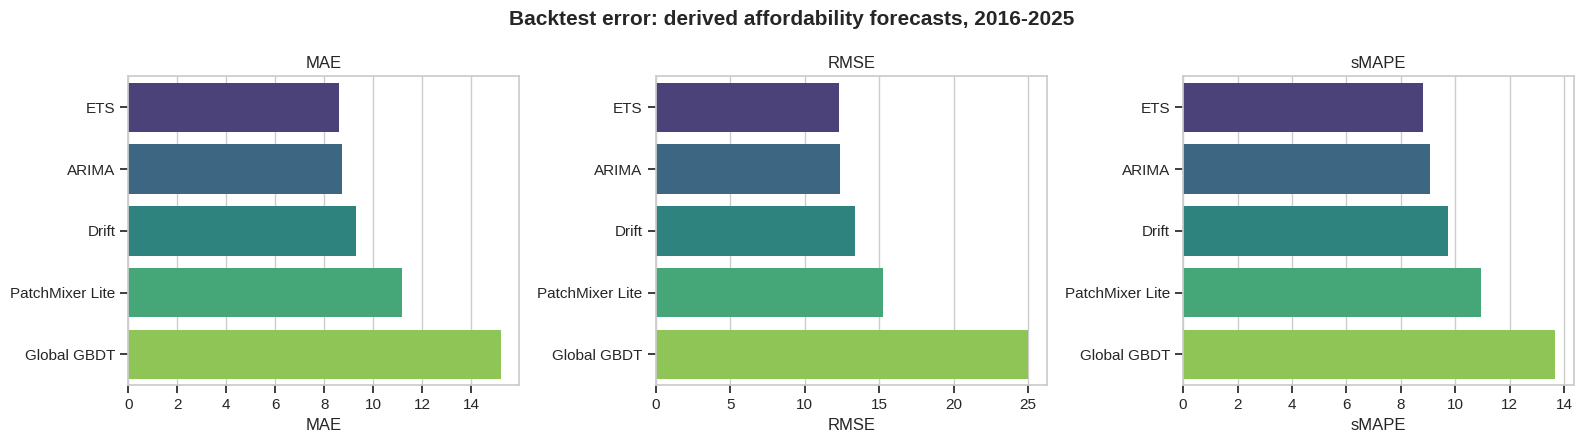

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, ["MAE", "RMSE", "sMAPE"]):
    sns.barplot(data=metrics_df, x=metric, y="model", ax=ax, palette="viridis")
    ax.set_title(metric)
    ax.set_ylabel("")
plt.suptitle("Backtest error: derived affordability forecasts, 2016-2025", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()

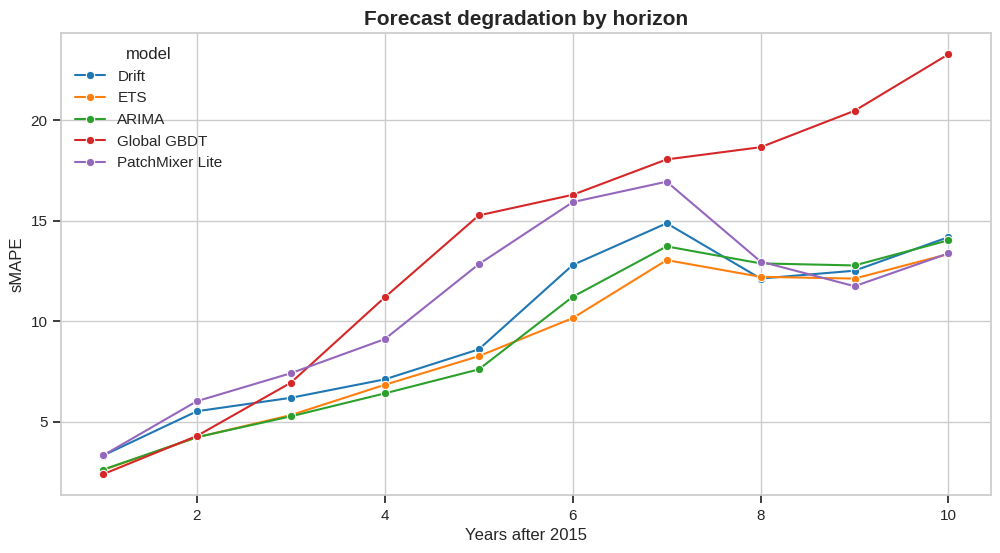

In [14]:
by_horizon = []
for name, pred_aff in backtest_affordability_forecasts.items():
    merged = pred_aff.merge(
        actual_backtest[["country", "iso", "year", "affordability_proxy"]],
        on=["country", "iso", "year"],
        how="inner",
    )
    merged["horizon"] = merged["year"] - ORIGIN
    for horizon, g in merged.groupby("horizon"):
        by_horizon.append({
            "model": name,
            "horizon": horizon,
            "sMAPE": smape(g["affordability_proxy"], g["affordability_hat"]),
            "MAE": mean_absolute_error(g["affordability_proxy"], g["affordability_hat"]),
        })

by_horizon = pd.DataFrame(by_horizon)

plt.figure(figsize=(12, 6))
sns.lineplot(data=by_horizon, x="horizon", y="sMAPE", hue="model", marker="o")
plt.title("Forecast degradation by horizon", fontsize=15, weight="bold")
plt.xlabel("Years after 2015")
plt.ylabel("sMAPE")
plt.show()

## 10. Country-Level Backtest Diagnostics

The plot below compares actual affordability against the strongest backtest models for selected countries. Change `COUNTRIES_TO_PLOT` to inspect others.

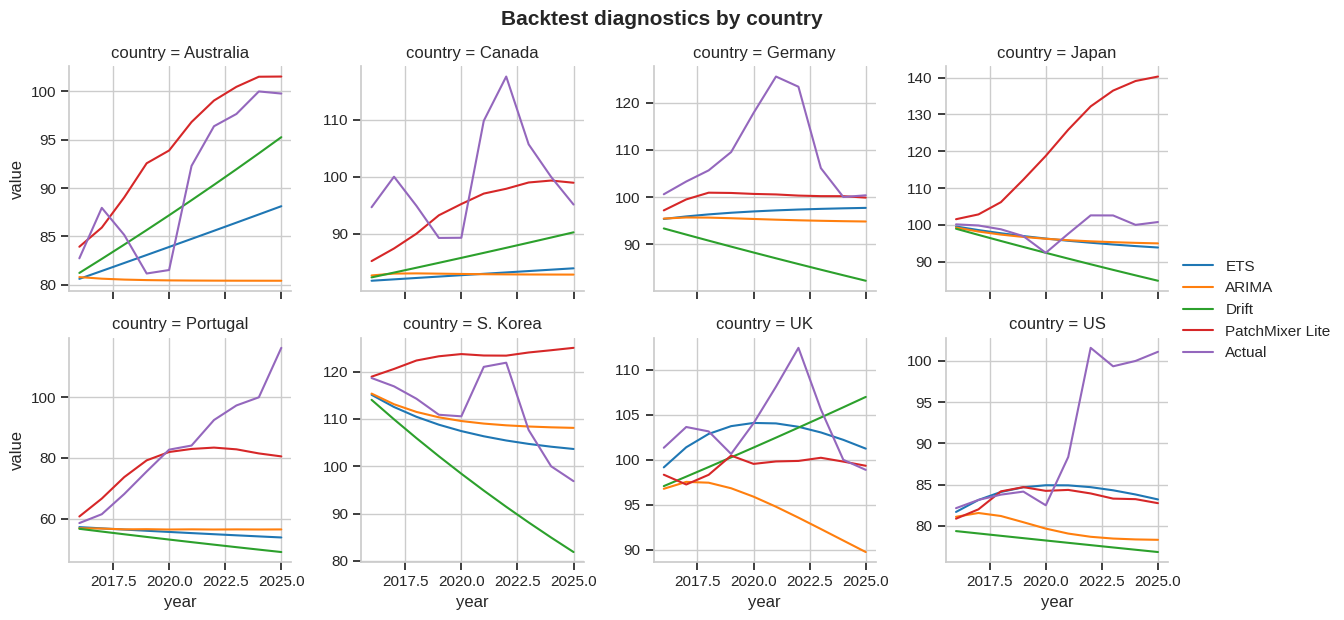

In [15]:
COUNTRIES_TO_PLOT = ["Australia", "Canada", "Germany", "Japan", "Portugal", "S. Korea", "US", "UK"]
models_to_plot = metrics_df["model"].head(min(4, len(metrics_df))).tolist()

plot_rows = []
for name in models_to_plot:
    tmp = backtest_affordability_forecasts[name].copy()
    tmp["series"] = name
    plot_rows.append(tmp[["country", "year", "affordability_hat", "series"]].rename(columns={"affordability_hat": "value"}))

actual_rows = actual_backtest[["country", "year", "affordability_proxy"]].copy()
actual_rows["series"] = "Actual"
actual_rows = actual_rows.rename(columns={"affordability_proxy": "value"})
plot_df = pd.concat(plot_rows + [actual_rows[["country", "year", "value", "series"]]], ignore_index=True)
plot_df = plot_df[plot_df["country"].isin(COUNTRIES_TO_PLOT)]

g = sns.FacetGrid(plot_df, col="country", col_wrap=4, height=3.0, sharey=False)
g.map_dataframe(sns.lineplot, x="year", y="value", hue="series", style="series", markers=False, dashes=False)
g.add_legend()
g.fig.suptitle("Backtest diagnostics by country", y=1.03, fontsize=15, weight="bold")
plt.show()

## 11. Refit Through 2025 and Forecast 2026-2035

We now refit every available model on the full panel through 2025 and produce 10-year forecasts.

In [16]:
future_component_forecasts = {}
future_affordability_forecasts = {}

for name, fn in model_functions.items():
    print(f"Forecasting 2026-2035 with {name}...")
    pred_components = fn(panel, FORECAST_ORIGIN, FORECAST_HORIZON)
    pred_aff = component_forecasts_to_affordability(pred_components)
    future_component_forecasts[name] = pred_components
    future_affordability_forecasts[name] = pred_aff

future_all = pd.concat(
    [add_model_name(df, name) for name, df in future_affordability_forecasts.items()],
    ignore_index=True,
)

future_all.head()

Forecasting 2026-2035 with Drift...
Forecasting 2026-2035 with ETS...
Forecasting 2026-2035 with ARIMA...
Forecasting 2026-2035 with Global GBDT...
Forecasting 2026-2035 with PatchMixer Lite...


,country,iso,year,real_house_price_index_hat,real_personal_disposable_income_hat,affordability_hat,model
0,Australia,AUS,2026,105.76,104.04,101.65,Drift
1,Australia,AUS,2027,109.07,105.32,103.57,Drift
2,Australia,AUS,2028,112.49,106.61,105.52,Drift
3,Australia,AUS,2029,116.02,107.93,107.50,Drift
4,Australia,AUS,2030,119.66,109.26,109.52,Drift


## 12. Error-Weighted Ensemble and Model-Spread Intervals

The ensemble weights models by inverse backtest sMAPE. The interval shown here is not a formal Bayesian credible interval. It is a model-spread interval: a practical way to show structural uncertainty across modeling assumptions.

In [17]:
weights = metrics_df.set_index("model")["sMAPE"].rpow(-1)
weights = weights / weights.sum()
weights = weights.rename("weight").reset_index()

print("Model weights from inverse backtest sMAPE:")
display(weights)

future_weighted = future_all.merge(weights, on="model", how="left")
ensemble = (
    future_weighted
    .assign(weighted_affordability=lambda x: x["affordability_hat"] * x["weight"])
    .groupby(["country", "iso", "year"], as_index=False)
    .agg(affordability_hat=("weighted_affordability", "sum"))
)
ensemble["model"] = "Error-weighted ensemble"

spread = (
    future_all
    .groupby(["country", "iso", "year"], as_index=False)
    .agg(
        p10=("affordability_hat", lambda s: np.percentile(s, 10)),
        p50=("affordability_hat", "median"),
        p90=("affordability_hat", lambda s: np.percentile(s, 90)),
        min_model=("affordability_hat", "min"),
        max_model=("affordability_hat", "max"),
    )
)

rank_2035 = ensemble[ensemble["year"] == 2035].sort_values("affordability_hat", ascending=False)
rank_2035.head(15)

Model weights from inverse backtest sMAPE:


,model,weight
0,ETS,NaN
1,ARIMA,NaN
2,Drift,NaN
3,PatchMixer Lite,NaN
4,Global GBDT,NaN


,country,iso,year,affordability_hat,model
9,Australia,AUS,2035,0.00,Error-weighted ensemble
19,Belgium,BEL,2035,0.00,Error-weighted ensemble
29,Canada,CAN,2035,0.00,Error-weighted ensemble
39,Colombia,COL,2035,0.00,Error-weighted ensemble
49,Croatia,HRV,2035,0.00,Error-weighted ensemble
59,Denmark,DNK,2035,0.00,Error-weighted ensemble
69,Finland,FIN,2035,0.00,Error-weighted ensemble
79,France,FRA,2035,0.00,Error-weighted ensemble
89,Germany,DEU,2035,0.00,Error-weighted ensemble
99,Ireland,IRL,2035,0.00,Error-weighted ensemble


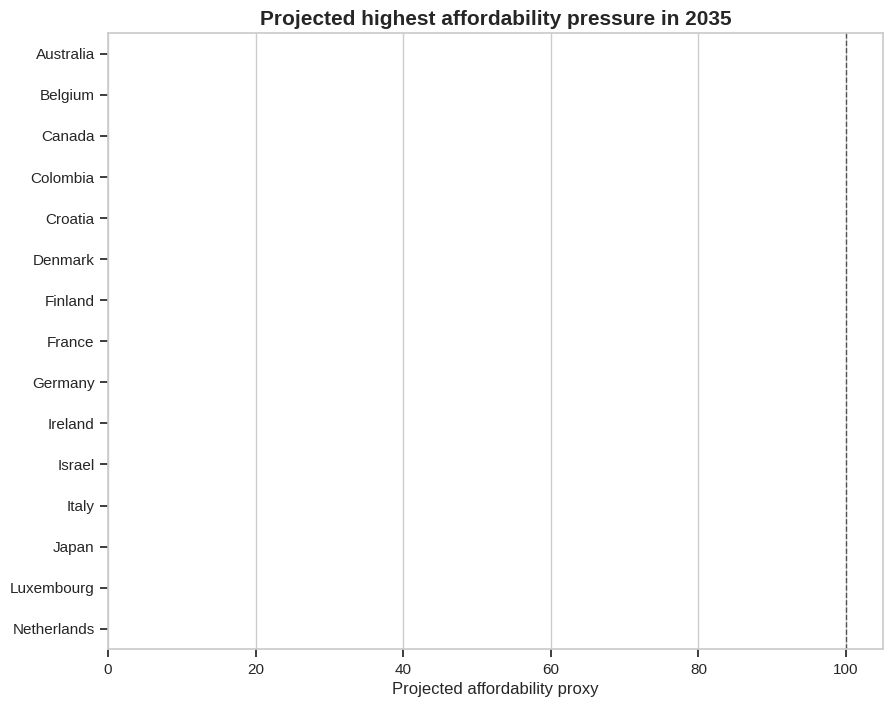

In [18]:
plt.figure(figsize=(10, 8))
sns.barplot(
    data=rank_2035.head(15),
    x="affordability_hat",
    y="country",
    palette="rocket",
)
plt.axvline(100, color="black", lw=1, ls="--", alpha=0.6)
plt.title("Projected highest affordability pressure in 2035", fontsize=15, weight="bold")
plt.xlabel("Projected affordability proxy")
plt.ylabel("")
plt.show()

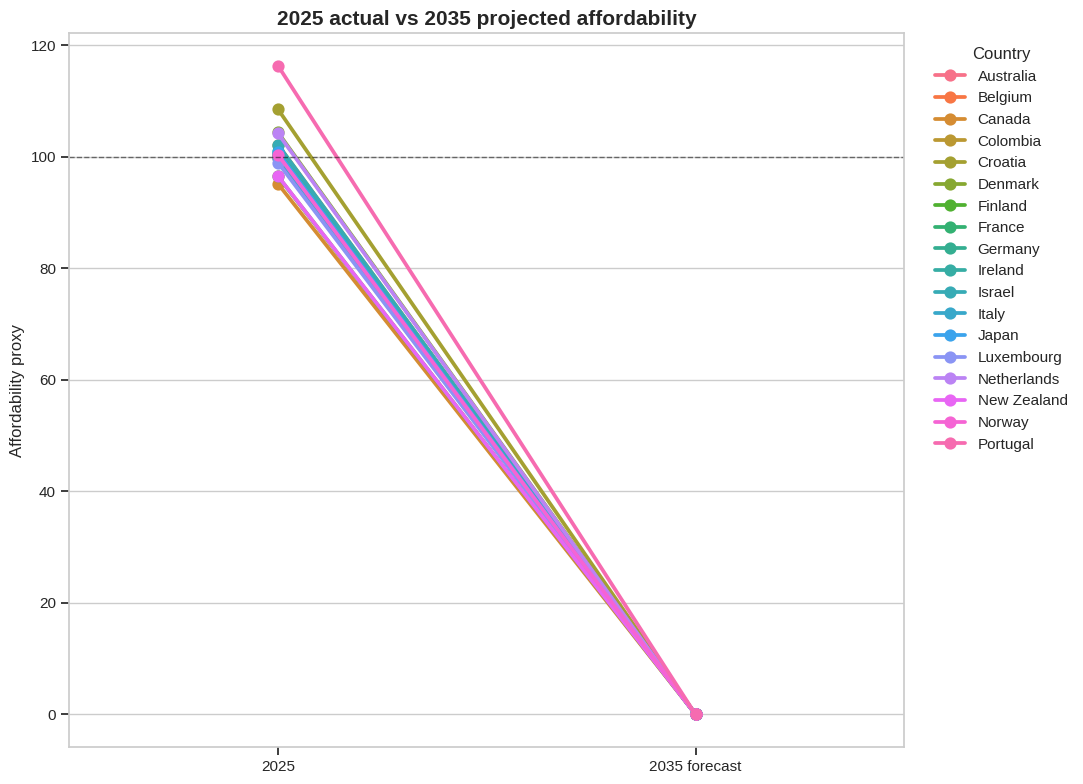

In [19]:
latest_actual = raw[raw["year"] == FORECAST_ORIGIN][["country", "iso", "year", "affordability_proxy"]].rename(
    columns={"affordability_proxy": "affordability"}
)
latest_actual["period"] = str(FORECAST_ORIGIN)

projected_2035 = rank_2035[["country", "iso", "year", "affordability_hat"]].rename(
    columns={"affordability_hat": "affordability"}
)
projected_2035["period"] = "2035 forecast"

slope = pd.concat([
    latest_actual[["country", "period", "affordability"]],
    projected_2035[["country", "period", "affordability"]],
])

slope_order = projected_2035.sort_values("affordability", ascending=False)["country"].head(18).tolist()
slope = slope[slope["country"].isin(slope_order)]

plt.figure(figsize=(11, 8))
sns.pointplot(data=slope, x="period", y="affordability", hue="country", order=[str(FORECAST_ORIGIN), "2035 forecast"])
plt.axhline(100, color="black", lw=1, ls="--", alpha=0.5)
plt.title("2025 actual vs 2035 projected affordability", fontsize=15, weight="bold")
plt.xlabel("")
plt.ylabel("Affordability proxy")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Country")
plt.tight_layout()
plt.show()

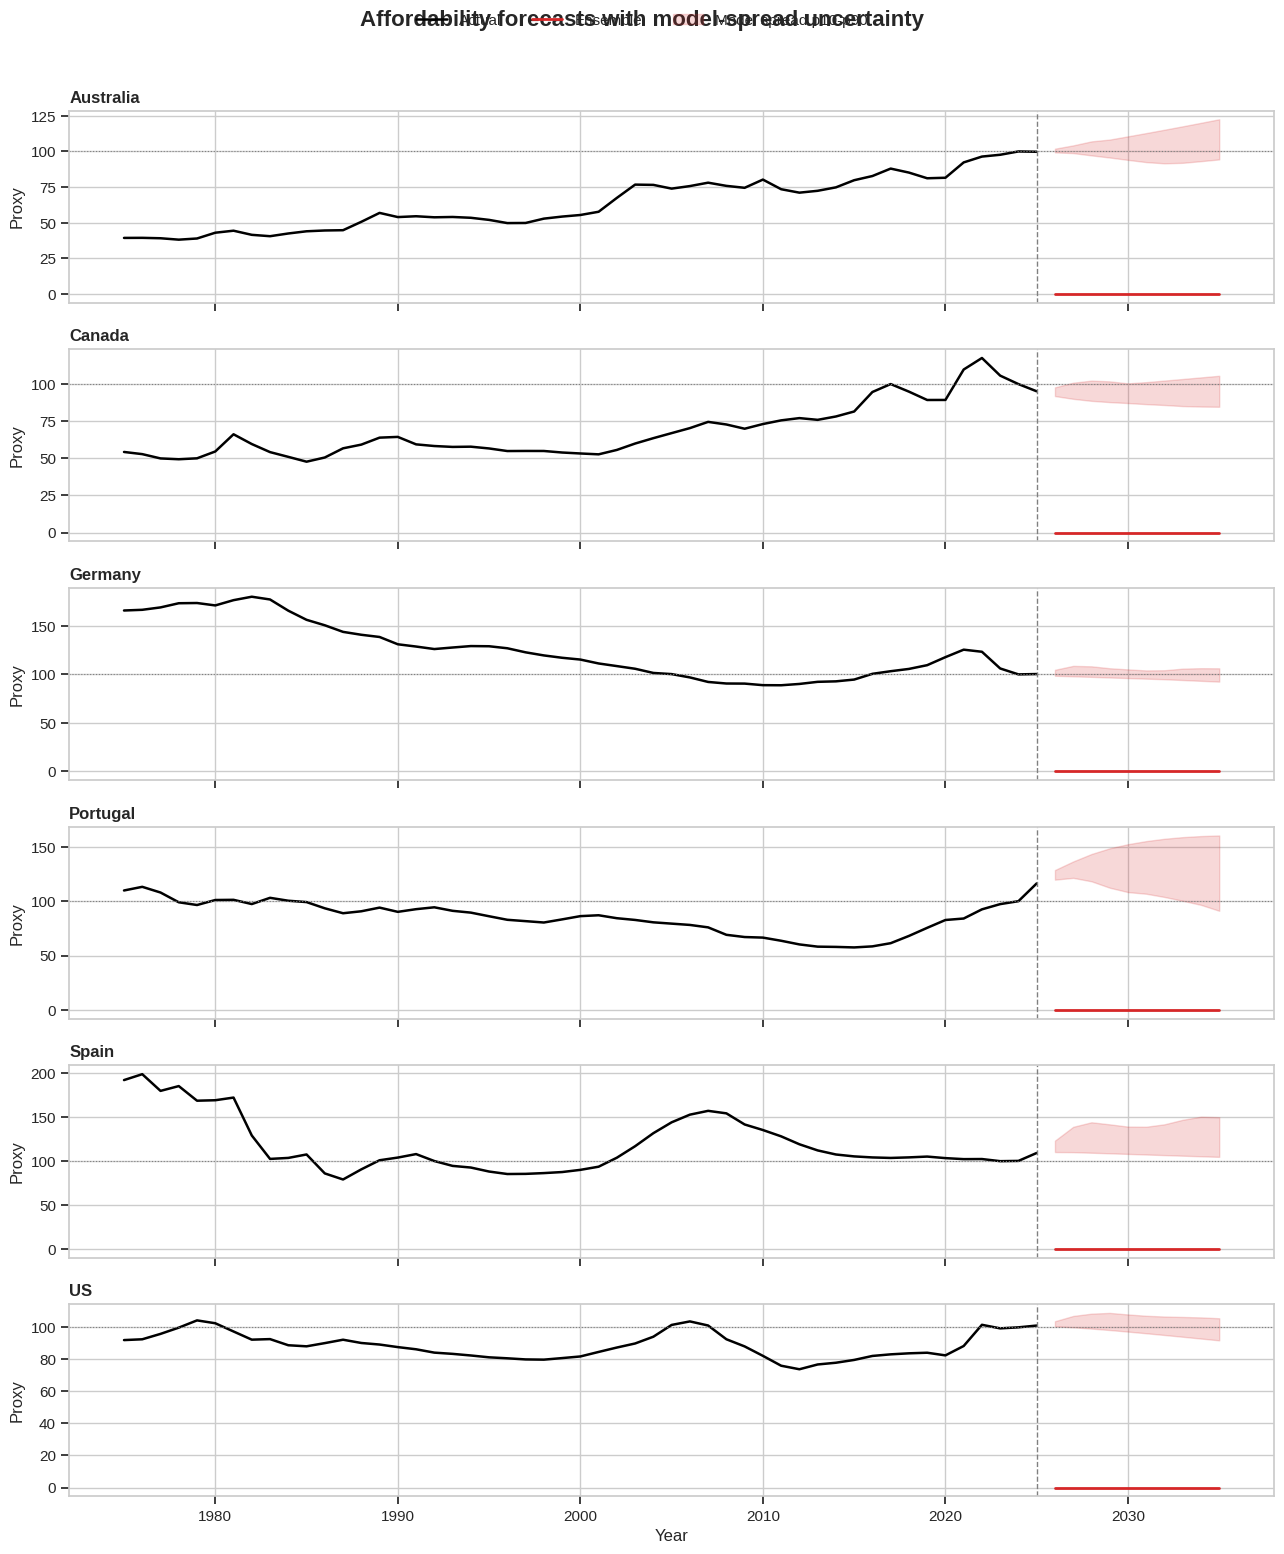

In [20]:
FAN_COUNTRIES = ["Australia", "Canada", "Germany", "Portugal", "Spain", "US"]

history_for_fan = raw[raw["country"].isin(FAN_COUNTRIES)][["country", "year", "affordability_proxy"]].copy()

fig, axes = plt.subplots(len(FAN_COUNTRIES), 1, figsize=(13, 2.6 * len(FAN_COUNTRIES)), sharex=True)
if len(FAN_COUNTRIES) == 1:
    axes = [axes]

for ax, country in zip(axes, FAN_COUNTRIES):
    hist = history_for_fan[history_for_fan["country"] == country]
    sp = spread[spread["country"] == country]
    ens = ensemble[ensemble["country"] == country]

    ax.plot(hist["year"], hist["affordability_proxy"], color="black", lw=1.8, label="Actual")
    ax.plot(ens["year"], ens["affordability_hat"], color="#d62728", lw=2.0, label="Ensemble")
    ax.fill_between(sp["year"], sp["p10"], sp["p90"], color="#d62728", alpha=0.18, label="Model spread p10-p90")
    ax.axvline(FORECAST_ORIGIN, color="gray", lw=1, ls="--")
    ax.axhline(100, color="gray", lw=0.8, ls=":")
    ax.set_title(country, loc="left", weight="bold")
    ax.set_ylabel("Proxy")

axes[-1].set_xlabel("Year")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False)
fig.suptitle("Affordability forecasts with model-spread uncertainty", y=0.995, fontsize=16, weight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

## 13. Export Forecast Tables

Kaggle readers often want the forecast table. This cell writes compact CSV outputs to the notebook working directory.

In [21]:
output_dir = Path(".")

ensemble_out = ensemble.sort_values(["country", "year"])
spread_out = spread.sort_values(["country", "year"])
model_out = future_all.sort_values(["model", "country", "year"])

ensemble_out.to_csv(output_dir / "affordability_forecast_ensemble_2026_2035.csv", index=False)
spread_out.to_csv(output_dir / "affordability_forecast_model_spread_2026_2035.csv", index=False)
model_out.to_csv(output_dir / "affordability_forecast_by_model_2026_2035.csv", index=False)

print("Saved:")
print("- affordability_forecast_ensemble_2026_2035.csv")
print("- affordability_forecast_model_spread_2026_2035.csv")
print("- affordability_forecast_by_model_2026_2035.csv")

Saved:
- affordability_forecast_ensemble_2026_2035.csv
- affordability_forecast_model_spread_2026_2035.csv
- affordability_forecast_by_model_2026_2035.csv
